In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# LOAD THE DATASET
df = pd.read_csv("train.csv")


In [10]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [11]:
df.shape

(891, 12)

BASIC DATA EXPLORATION

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [13]:
df.columns.tolist() # column names

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Cabin',
 'Embarked']

In [14]:
df.describe(include="all") # discriptive statistics

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [15]:
df.isnull().sum() # missing values

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [17]:
print((df.isnull().mean() * 100).round(2)) # missing value percentages

PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64


In [18]:
df.duplicated().sum() # duplicated values

np.int64(0)

In [19]:
df["Survived"].value_counts() # survival distribution

,count
Survived,
0,549
1,342


In [20]:
plt.figure(figsize=(7, 5))

<Figure size 700x500 with 0 Axes>

<Figure size 700x500 with 0 Axes>

<Axes: xlabel='Survived', ylabel='count'>

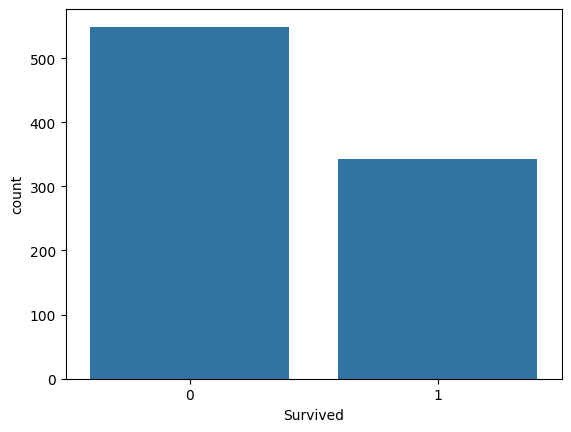

In [21]:
sns.countplot(data=df, x="Survived")

Text(0, 0.5, 'Number of Passengers')

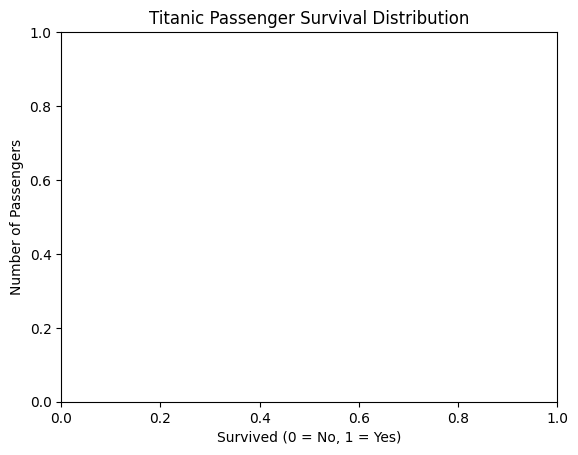

In [22]:
plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")


In [23]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

HANDLE MISSING VALUES

In [24]:
df.isnull().sum() # missing values before preprocessing

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [27]:
selected_features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]
print(df[selected_features].isnull().sum()) # missing values in selected features

Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

MISSING VALUE HANDLING STRATEGY:
Numerical columns: Median Imputation
Categorical columns: Most Frequent Imputation

Actual imputation will be performed
inside the preprocessing pipeline in Step 8.


ENCODE CATEGORICAL VARIABLES

In [28]:
data = df.copy()

feature_columns = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

target_column = "Survived"

numerical_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features = [
    "Sex",
    "Embarked"
]
print(numerical_features)
print(categorical_features)

['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
['Sex', 'Embarked']


SPLIT FEATURES (X) AND TARGET (y)

In [29]:
X = data[feature_columns]
y = data[target_column]

In [30]:
print(X.shape)
print(y.shape)

(891, 7)
(891,)


In [31]:
display(X.head())

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


TRAIN-TEST SPLIT

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [33]:
X_train.shape

(712, 7)

In [34]:
X_test.shape

(179, 7)

In [35]:
y_train.shape

(712,)

In [36]:
y_test.shape

(179,)

APPLY RANDOM FOREST MODEL

In [37]:
# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

In [38]:
# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

In [39]:
# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [40]:
# Initialize Random Forest Classifier
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

In [41]:
# Complete machine learning pipeline
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", random_forest)
])
print("Random Forest Model Initialized!")

Random Forest Model Initialized!


TRAIN THE MODEL

In [42]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Parch', 'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Sex', 'Embarked'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', n_jobs=-1,
                                        random_state=42))])

MAKE PREDICTIONS

In [44]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})
results.head(10) #first ten predictions

,Actual,Predicted
0,0,0
1,0,0
2,1,0
3,0,0
4,1,1
5,1,0
6,1,1
7,0,1
8,0,0
9,0,0


EVALUATE THE MODEL

In [45]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, zero_division=0
)
recall = recall_score(
    y_test, y_pred, zero_division=0
)
f1 = f1_score(
    y_test, y_pred, zero_division=0
)


In [46]:
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Accuracy:  0.8268
Precision: 0.8167
Recall:    0.7101
F1-Score:  0.7597


In [47]:
print(classification_report(y_test, y_pred)) # classification report

              precision    recall  f1-score   support

           0       0.83      0.90      0.86       110
           1       0.82      0.71      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179



Confusion Matrix

<Axes: >

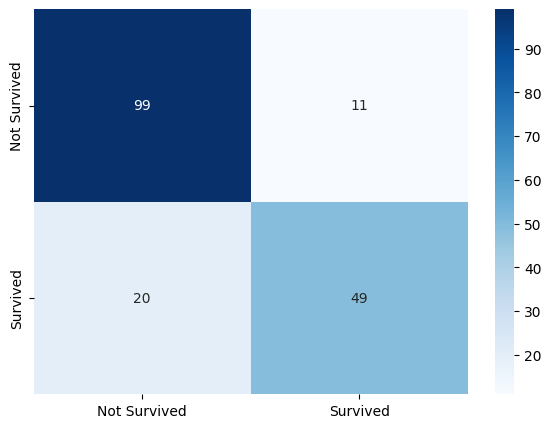

In [48]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

Text(0, 0.5, 'Actual Class')

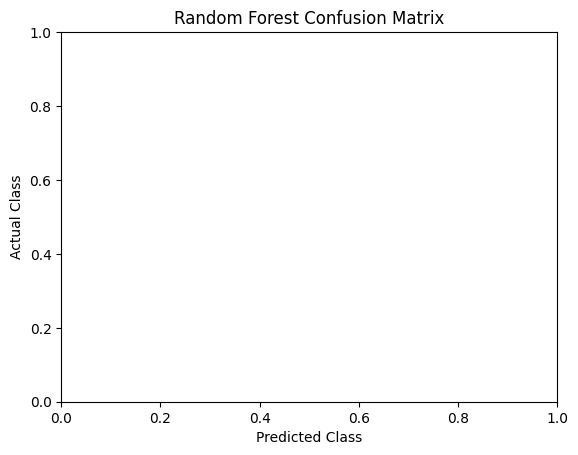

In [49]:
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

In [50]:
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

FEATURE IMPORTANCE

In [51]:
feature_names = model.named_steps[
    "preprocessing"
].get_feature_names_out()

importances = model.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

In [52]:
display(feature_importance)

,Feature,Importance
4,num__Fare,0.262894
1,num__Age,0.255058
5,cat__Sex_female,0.157775
6,cat__Sex_male,0.127494
0,num__Pclass,0.078825
2,num__SibSp,0.046493
3,num__Parch,0.035771
9,cat__Embarked_S,0.016303
7,cat__Embarked_C,0.013343
8,cat__Embarked_Q,0.006045


In [53]:
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

<Axes: xlabel='Importance', ylabel='Feature'>

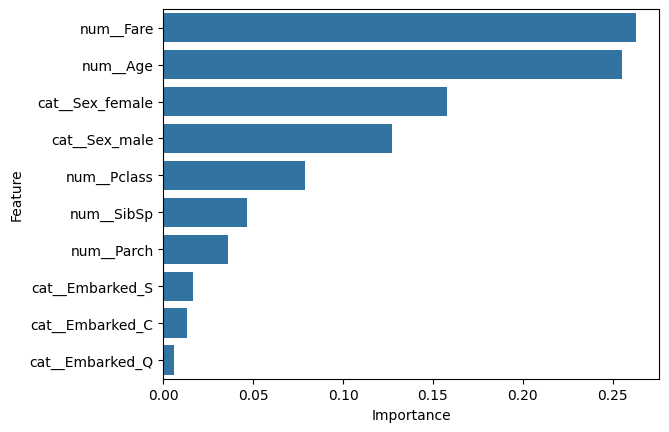

In [54]:
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

Text(0, 0.5, 'Feature')

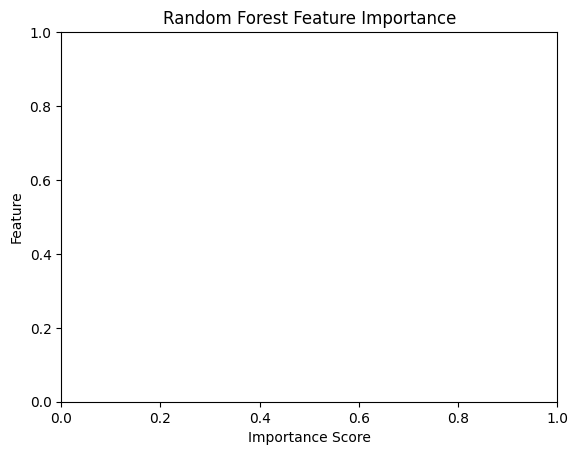

In [55]:
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")


In [56]:
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

PROJECT CONCLUSION

In [57]:
top_feature = feature_importance.iloc[0]["Feature"]

In [58]:
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Accuracy:  0.8268
Precision: 0.8167
Recall:    0.7101
F1-Score:  0.7597


In [59]:
print("Most Important Feature:", top_feature)

Most Important Feature: num__Fare


In [60]:
print("""
The Random Forest model was used to classify
passenger survival on the Titanic dataset.

The dataset was explored and missing values were
handled using appropriate imputation methods.

Categorical variables were encoded using
One-Hot Encoding.

The dataset was divided into training and
testing sets using an 80:20 ratio.

The model was evaluated using Accuracy,
Precision, Recall, F1-Score, and a
Confusion Matrix.

Feature importance was examined to understand
which variables contributed most to predictions.

The model demonstrates the use of Random Forest
for a classification problem involving historical
passenger data.
""")

print("\nProject Execution Completed Successfully!")


The Random Forest model was used to classify
passenger survival on the Titanic dataset.

The dataset was explored and missing values were
handled using appropriate imputation methods.

Categorical variables were encoded using
One-Hot Encoding.

The dataset was divided into training and
testing sets using an 80:20 ratio.

The model was evaluated using Accuracy,
Precision, Recall, F1-Score, and a
Confusion Matrix.

Feature importance was examined to understand
which variables contributed most to predictions.

The model demonstrates the use of Random Forest
for a classification problem involving historical
passenger data.


Project Execution Completed Successfully!
